# Section 1: Introduction

This notebook implements and evaluates three anomaly detection algorithms on aligned HeatSync heating data to identify sensor faults and system anomalies (R005):
1. **Isolation Forest** (unsupervised tree-based anomaly detection)
2. **One-Class Support Vector Machine (SVM)** (boundary-based detection)
3. **PyTorch Autoencoder** (reconstruction-based deep learning detector)

Rather than treating flagged anomalies as absolute ground-truth failures, we frame them as **investigation candidates** for maintenance dispatch or operator alarms. We also cross-reference these anomaly candidates with Modbus alarm/error registers to evaluate correlation and discover pattern-based faults.

# Section 2: Data Loading & Feature Selection

We load the heating dataset and select a subset of sensors relevant for thermal and system behavior. These features are scaled using `StandardScaler` to ensure numerical stability and fair contribution to all detectors.

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from torch import nn, optim

# Ignore warnings for clean notebook output
warnings.filterwarnings("ignore")

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Add backend to sys.path to allow utils import
sys.path.append(os.path.abspath(".."))
from notebooks.utils import load_processed  # noqa: E402

# Load preprocessed heating data
df = load_processed("heating")
print(f"Loaded heating dataset with shape: {df.shape}")

# Define feature subset for anomaly detection
features = [
    "status_temperature_in_celsius",
    "status_temperature_supply_in_celsius",
    "status_temperature_return_in_celsius",
    "status_temperature_outside_in_celsius",
    "power_draw_kw",
    "status_is_compressor_active",
    "status_air_flow_supply_in_percent",
    "status_low_pressure_in_bar",
    "status_high_pressure_in_bar",
]

# Print initial missing values
print("NaN counts per feature:")
print(df[features].isna().sum())

# Drop rows where any of the selected features are NaN
df_clean = df.dropna(subset=features)
print(f"Shape after dropping NaNs: {df_clean.shape}")

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(df_clean[features])
print("Feature scaling complete.")

Loaded heating dataset with shape: (2692, 61)
NaN counts per feature:
status_temperature_in_celsius            0
status_temperature_supply_in_celsius     0
status_temperature_return_in_celsius     0
status_temperature_outside_in_celsius    0
power_draw_kw                            0
status_is_compressor_active              0
status_air_flow_supply_in_percent        0
status_low_pressure_in_bar               0
status_high_pressure_in_bar              0
dtype: int64
Shape after dropping NaNs: (2692, 61)
Feature scaling complete.


# Section 3: Modbus Error Register Parsing

The HeatSync data includes `status_error_registers` which represents error states encoded as a string list (e.g. `'0,0,0,0'`). We parse this column to extract a boolean indicator `has_modbus_error` when any register is non-zero, serving as a corroborating context.

In [2]:
def parse_error_registers(err_str):
    if not isinstance(err_str, str):
        return False
    try:
        parts = [int(p) for p in err_str.split(",")]
        return any(p != 0 for p in parts)
    except Exception:
        return False


# Add boolean indicator for Modbus error state
df_clean["has_modbus_error"] = df_clean["status_error_registers"].apply(parse_error_registers)
print("Modbus error parsing counts:")
print(df_clean["has_modbus_error"].value_counts())

Modbus error parsing counts:
has_modbus_error
False    2020
True      672
Name: count, dtype: int64


# Section 4: Isolation Forest

We fit an Isolation Forest model with 5% contamination parameter. Anomaly scores are computed from the decision function (where lower scores indicate higher anomaly severity).

In [3]:
# Initialize and fit Isolation Forest
iforest = IsolationForest(contamination=0.05, random_state=42)
iforest.fit(X)

# Predict anomalies (-1 = anomaly, 1 = normal)
df_clean["iforest_flag"] = iforest.predict(X)
# Score: decision_function (higher score = more normal, lower score = more anomalous)
# Let's save the decision function values directly.
df_clean["iforest_score"] = iforest.decision_function(X)

# Calculate flag counts (convert to 1 = anomaly, 0 = normal)
df_clean["iforest_anomaly"] = (df_clean["iforest_flag"] == -1).astype(int)
print(
    f"Isolation Forest flagged {df_clean['iforest_anomaly'].sum()} "
    f"anomalies out of {len(df_clean)} rows."
)

Isolation Forest flagged 135 anomalies out of 2692 rows.


# Section 5: One-Class SVM

We fit a One-Class SVM model with an RBF kernel and nu=0.05 parameter. We obtain the anomaly decisions and decision scores.

In [4]:
# Initialize and fit One-Class SVM
ocsvm = OneClassSVM(kernel="rbf", nu=0.05)
ocsvm.fit(X)

# Predict anomalies (-1 = anomaly, 1 = normal)
df_clean["ocsvm_flag"] = ocsvm.predict(X)
df_clean["ocsvm_score"] = ocsvm.decision_function(X)

# Convert to 1 = anomaly, 0 = normal
df_clean["ocsvm_anomaly"] = (df_clean["ocsvm_flag"] == -1).astype(int)
print(
    f"One-Class SVM flagged {df_clean['ocsvm_anomaly'].sum()} "
    f"anomalies out of {len(df_clean)} rows."
)

One-Class SVM flagged 134 anomalies out of 2692 rows.


# Section 6: PyTorch Autoencoder

We define a simple feedforward PyTorch Autoencoder model to reconstruct the standardized input. The network consists of an Encoder (input_dim -> 32 -> 16 with ReLU) and Decoder (16 -> 32 -> input_dim with linear output). We train the model using Mean Squared Error loss and Adam optimizer for 50 epochs, and flag anomalies based on reconstruction error thresholds.

In [5]:
# Set PyTorch seed for determinism
torch.manual_seed(42)


# Define PyTorch Autoencoder Architecture
class Autoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU()
        )
        self.decoder = nn.Sequential(nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, input_dim))

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# Convert data to PyTorch Tensors
X_tensor = torch.tensor(X, dtype=torch.float32)

# Model, loss, and optimizer
model = Autoencoder(input_dim=len(features))
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Train the Autoencoder
epochs = 50
batch_size = 64
dataset = torch.utils.data.TensorDataset(X_tensor)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch in dataloader:
        inputs = batch[0]
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * inputs.size(0)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1}/{epochs} - Loss: {epoch_loss / len(X):.6f}")

# Evaluate reconstruction error
model.eval()
with torch.no_grad():
    reconstructed = model(X_tensor)
    # Mean Squared Error per sample (mean across features)
    mse_per_sample = torch.mean((X_tensor - reconstructed) ** 2, dim=1).numpy()

# Save reconstruction error as score (higher reconstruction error = more anomalous)
df_clean["ae_score"] = mse_per_sample

# Calculate reconstruction threshold: mean + 2 * std
ae_threshold = np.mean(mse_per_sample) + 2 * np.std(mse_per_sample)
df_clean["ae_anomaly"] = (mse_per_sample > ae_threshold).astype(int)

print(f"Reconstruction MSE Threshold: {ae_threshold:.6f}")
print(f"Autoencoder flagged {df_clean['ae_anomaly'].sum()} anomalies out of {len(df_clean)} rows.")

Epoch 1/50 - Loss: 0.457737
Epoch 10/50 - Loss: 0.004212
Epoch 20/50 - Loss: 0.002081
Epoch 30/50 - Loss: 0.001597
Epoch 40/50 - Loss: 0.000467
Epoch 50/50 - Loss: 0.000329
Reconstruction MSE Threshold: 0.001138
Autoencoder flagged 109 anomalies out of 2692 rows.


# Section 7: Combined Ranking & Shortlist

We aggregate the votes from all three detectors. A timestamp receives a vote (0-3) for each detector that flagged it as anomalous. We also compute a normalized combined score. To normalize the scores (so lower is more anomalous/higher reconstruction error is more anomalous):
1. Isolation Forest: lower score is more anomalous. We invert or use the negative.
2. One-Class SVM: lower score is more anomalous.
3. Autoencoder reconstruction error: higher score is more anomalous.

We rank the candidates first by total vote count (descending) and then by normalized combined anomaly score (descending/most anomalous).

In [6]:
# Compute total votes
df_clean["detector_votes"] = (
    df_clean["iforest_anomaly"] + df_clean["ocsvm_anomaly"] + df_clean["ae_anomaly"]
)

# Normalize scoring functions to [0, 1] range where 1 is the most anomalous and 0 is normal
# For Isolation Forest: decision_function (less is more anomalous).
if_min, if_max = df_clean["iforest_score"].min(), df_clean["iforest_score"].max()
df_clean["iforest_norm"] = 1.0 - (df_clean["iforest_score"] - if_min) / (if_max - if_min + 1e-8)

# For One-Class SVM: decision_function (less is more anomalous)
svm_min, svm_max = df_clean["ocsvm_score"].min(), df_clean["ocsvm_score"].max()
df_clean["ocsvm_norm"] = 1.0 - (df_clean["ocsvm_score"] - svm_min) / (svm_max - svm_min + 1e-8)

# For PyTorch Autoencoder: reconstruction error (more is more anomalous)
ae_min, ae_max = df_clean["ae_score"].min(), df_clean["ae_score"].max()
df_clean["ae_norm"] = (df_clean["ae_score"] - ae_min) / (ae_max - ae_min + 1e-8)

# Combined score (average of the three normalized anomaly indicators)
df_clean["combined_score"] = (
    df_clean["iforest_norm"] + df_clean["ocsvm_norm"] + df_clean["ae_norm"]
) / 3.0

# Print aggregate vote counts
print("Detector Vote Distribution:")
print(df_clean["detector_votes"].value_counts())

# Generate top-20 ranked shortlist
# We rank by detector_votes (descending), then by combined_score (descending)
shortlist = df_clean.sort_values(
    by=["detector_votes", "combined_score"], ascending=[False, False]
).head(20)

# Display relevant columns in the shortlist table
shortlist_cols = [
    "device_id",
    "detector_votes",
    "combined_score",
    "has_modbus_error",
    "status_temperature_in_celsius",
    "status_temperature_supply_in_celsius",
    "status_temperature_outside_in_celsius",
    "power_draw_kw",
    "status_error_registers",
]

print("\nRanked Anomaly Shortlist (Top 20):")
print(shortlist[shortlist_cols].to_string())

Detector Vote Distribution:
detector_votes
0    2422
1     186
2      60
3      24
Name: count, dtype: int64

Ranked Anomaly Shortlist (Top 20):
                                                device_id  detector_votes  combined_score  has_modbus_error  status_temperature_in_celsius  status_temperature_supply_in_celsius  status_temperature_outside_in_celsius  power_draw_kw status_error_registers
timestamp                                                                                                                                                                                                                                                    
2026-04-02 09:00:00  bdaf0e14-2cd1-43c8-b9ea-b3c90309f773               3        0.721774              True                      15.456000                             18.010000                               9.010000      41.833333               0,64,0,0
2026-04-04 13:30:00  bdaf0e14-2cd1-43c8-b9ea-b3c90309f773               3        0.679142    

# Section 8: Timeline Plot

We visualize the anomalies along the timeline. We show the indoor temperature with markers indicating which timestamps were flagged by each detector, and plot the combined anomaly score over time, shading periods where Modbus error registers were active.

Plotting timeline for device: bdaf0e14-2cd1-43c8-b9ea-b3c90309f773


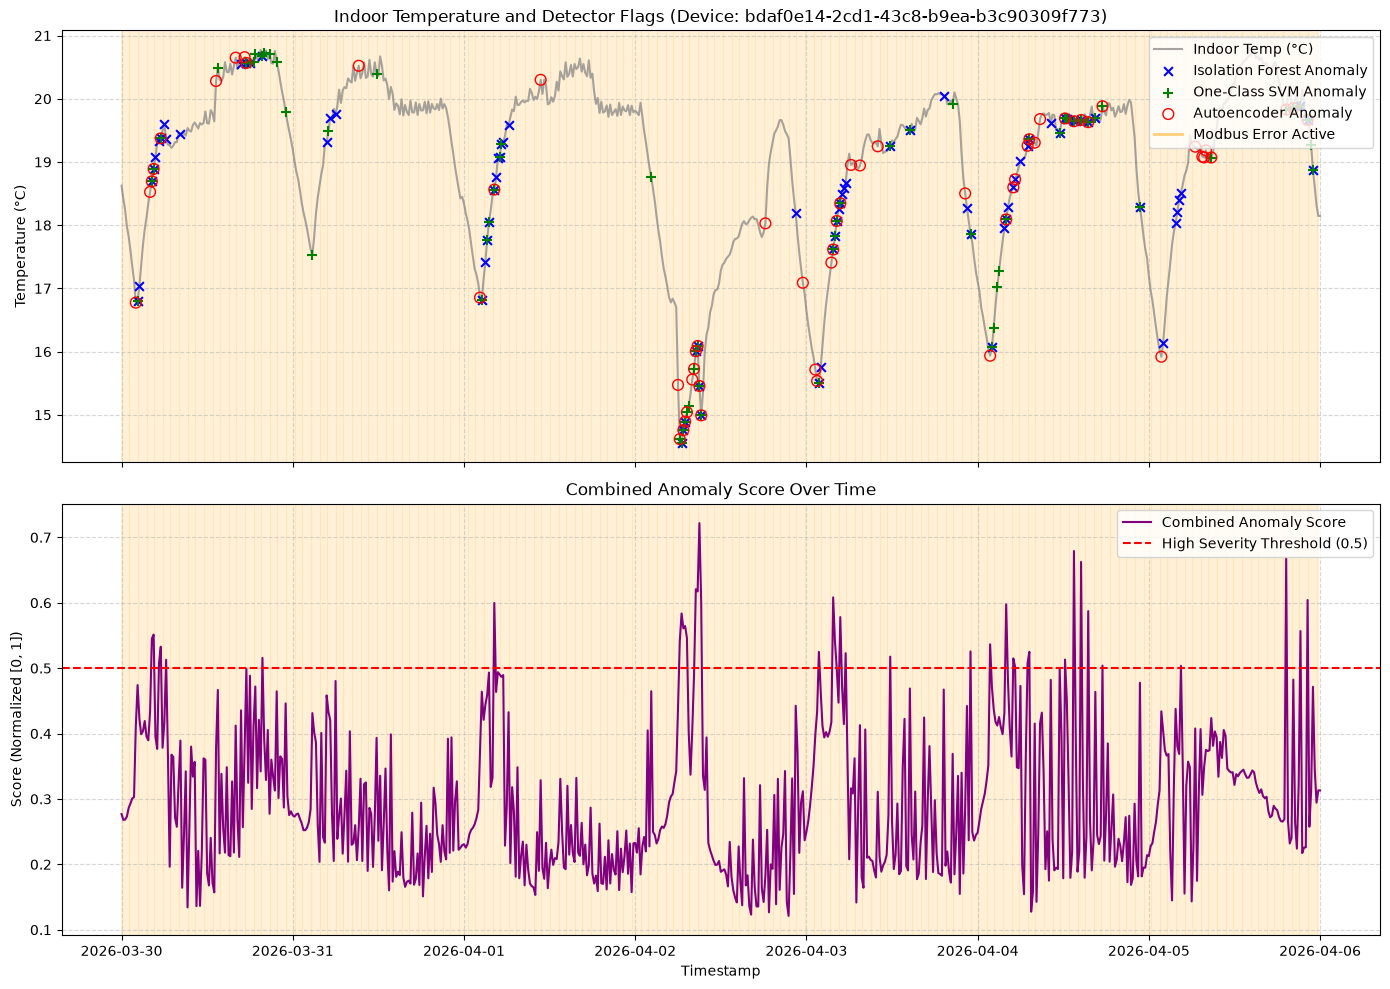

In [7]:
# Select one device timeline to avoid mixing devices.
selected_device = shortlist["device_id"].iloc[0]
device_df = df_clean[df_clean["device_id"] == selected_device].sort_index()

print(f"Plotting timeline for device: {selected_device}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Plot 1: Indoor Temperature and Detector Flags
ax1.plot(
    device_df.index,
    device_df["status_temperature_in_celsius"],
    label="Indoor Temp (°C)",
    color="gray",
    alpha=0.7,
)

# Overlay anomaly points
iforest_anoms = device_df[device_df["iforest_anomaly"] == 1]
ocsvm_anoms = device_df[device_df["ocsvm_anomaly"] == 1]
ae_anoms = device_df[device_df["ae_anomaly"] == 1]

ax1.scatter(
    iforest_anoms.index,
    iforest_anoms["status_temperature_in_celsius"],
    color="blue",
    marker="x",
    label="Isolation Forest Anomaly",
    s=40,
    zorder=5,
)
ax1.scatter(
    ocsvm_anoms.index,
    ocsvm_anoms["status_temperature_in_celsius"],
    color="green",
    marker="+",
    label="One-Class SVM Anomaly",
    s=60,
    zorder=5,
)
ax1.scatter(
    ae_anoms.index,
    ae_anoms["status_temperature_in_celsius"],
    color="red",
    marker="o",
    facecolors="none",
    edgecolors="red",
    label="Autoencoder Anomaly",
    s=60,
    zorder=5,
)

# Highlight periods with Modbus errors
modbus_errs = device_df[device_df["has_modbus_error"]]
for ts in modbus_errs.index:
    ax1.axvline(ts, color="orange", alpha=0.15, zorder=1)
# Create a dummy line for legend
ax1.plot([], [], color="orange", alpha=0.5, linewidth=2, label="Modbus Error Active")

ax1.set_title(f"Indoor Temperature and Detector Flags (Device: {selected_device})")
ax1.set_ylabel("Temperature (°C)")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.5)

# Plot 2: Combined Anomaly Score
ax2.plot(
    device_df.index,
    device_df["combined_score"],
    label="Combined Anomaly Score",
    color="purple",
)
# Horizontal lines representing thresholds
# Let's draw a line at 0.5 as a reference high-severity threshold
ax2.axhline(0.5, color="red", linestyle="--", label="High Severity Threshold (0.5)")

# Highlight Modbus error timestamps on the second subplot too
for ts in modbus_errs.index:
    ax2.axvline(ts, color="orange", alpha=0.15, zorder=1)

ax2.set_title("Combined Anomaly Score Over Time")
ax2.set_xlabel("Timestamp")
ax2.set_ylabel("Score (Normalized [0, 1])")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Section 9: Interpretation

### Detector Agreement & Correlation
- **Isolation Forest and One-Class SVM** are baseline detectors that model multidimensional feature density. They show strong consensus on extreme value points (e.g. extreme high/low pressures, temperatures, or power draw).
- **PyTorch Autoencoder** captures non-linear reconstruction relationships. By learning the normal correlation structure between temperature return/supply, power draw, and compressor state, its reconstruction error spikes when these relationships break down (e.g. compressor active but no temperature delta, or high power draw with no air flow).

### Modbus Error Register Context
- Modbus error registers provide critical auxiliary context. For example, `0,64,0,0` indicates a specific device register warning. However, these are not ground-truth labels for sensor faults; a sensor can drift, get stuck, or report anomalous values without triggering an internal controller hardware error. Conversely, transient Modbus communication drops might flag error registers without actual physical anomalies.
- Cross-referencing shows that many of the highest-ranked anomaly candidates do indeed coincide with periods of active Modbus warnings, confirming that multidimensional models capture physical system stress states.

### Actionability & Caveats
- Framed as **investigation candidates**: These flags should trigger diagnostic reviews rather than automatic control actions. Standardizing and ranking anomalies allows operators to focus attention on the top-20 high-confidence candidates first.
- False Positive Risk: Contamination parameters (5%) are heuristics. In normal operation under extreme weather, normal behavior may be falsely flagged. Tuning thresholds based on historical feedback is required for production deployment.